# Actors data analysis
we will analyze the actors dataset. We will usa a left-join operation to merge the actors and movies datasets, in order todiplay even the movie name in the final dataset.

In [52]:
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
import plotly.express as px

df_actors = pd.read_csv('data/actors.csv')
df_movies = pd.read_csv('data/movies.csv')
df_actors.head(15)

,id,name,role
0,1000001,Margot Robbie,Barbie
1,1000001,Ryan Gosling,Ken
2,1000001,America Ferrera,Gloria
3,1000001,Ariana Greenblatt,Sasha
4,1000001,Issa Rae,Barbie
5,1000001,Kate McKinnon,Barbie
6,1000001,Alexandra Shipp,Barbie
7,1000001,Emma Mackey,Barbie
8,1000001,Hari Nef,Barbie
9,1000001,Sharon Rooney,Barbie


- The dataframe obtained from the actors merged with movies dataset is shown down here.


In [53]:
df_movies_selected = df_movies[['id', 'name']]
df_merged_actors = pd.merge(df_actors, df_movies_selected, on='id', how='inner')
df_merged_actors.columns = ['id', 'actor', 'role', 'movie']
print("size of the dataset: ", df_merged_actors.shape)
df_merged_actors.head(15)

size of the dataset:  (5798450, 4)


,id,actor,role,movie
0,1000001,Margot Robbie,Barbie,Barbie
1,1000001,Ryan Gosling,Ken,Barbie
2,1000001,America Ferrera,Gloria,Barbie
3,1000001,Ariana Greenblatt,Sasha,Barbie
4,1000001,Issa Rae,Barbie,Barbie
5,1000001,Kate McKinnon,Barbie,Barbie
6,1000001,Alexandra Shipp,Barbie,Barbie
7,1000001,Emma Mackey,Barbie,Barbie
8,1000001,Hari Nef,Barbie,Barbie
9,1000001,Sharon Rooney,Barbie,Barbie


- We noticed that the dataset contains some duplicate values, on the column 'movie'. So there are some movies that have the same name but a different id, after a few checks we discovered that the duplicates with different id seems to be different movies, so we decided to keep them in the dataset.

In [54]:

df_movie_dup = df_movies['name'].duplicated()
val_dupl_in_movies = df_movie_dup.sum()
movie_na = df_movies['name'].isnull().sum()
print("number of duplicate movies: ", val_dupl_in_movies)
print("movie_na", movie_na)
df_merged_actors.nunique()

number of duplicate movies:  146175
movie_na 10


id        634302
actor    1600662
role     1920085
movie     541127
dtype: int64

For example, the movie "Barbie"  has different ids, with different duration etc... So we decided to keep them in the dataset.

In [55]:
df_movies[df_movies['name'] == 'Barbie']

,id,name,date,tagline,description,minute,rating
0,1000001,Barbie,2023.0,She's everything. He's just Ken.,Barbie and Ken are having the time of their li...,114.0,3.86
52040,1052041,Barbie,2011.0,This little girl dreams to be a barbie from th...,Soon-young lives with her mentally handicapped...,97.0,3.39
63518,1063519,Barbie,1977.0,NaN,Barbie comes home from shopping. She takes her...,10.0,3.12
147437,1147438,Barbie,2012.0,NaN,Soniya is going to be a first grader and she i...,13.0,NaN
506246,1506247,Barbie,2023.0,NaN,NaN,NaN,NaN
611658,1611659,Barbie,2023.0,NaN,A father buys a creepy doll for his daughter.,5.0,NaN


- Display the numbers of actors in each movie, (top 15)

In [56]:
df_actor_per_movie = df_merged_actors['movie'].value_counts().reset_index()
df_actor_per_movie.columns = ['movie', 'number of actors']
df_actor_per_movie.head(15)

,movie,number of actors
0,Les Misérables,653
1,Macbeth,644
2,Hamlet,627
3,A Christmas Carol,577
4,Home,560
5,Mother,560
6,Men at Arms,555
7,Cinderella,549
8,Brothers,510
9,First Love,498


<Axes: xlabel='movie'>

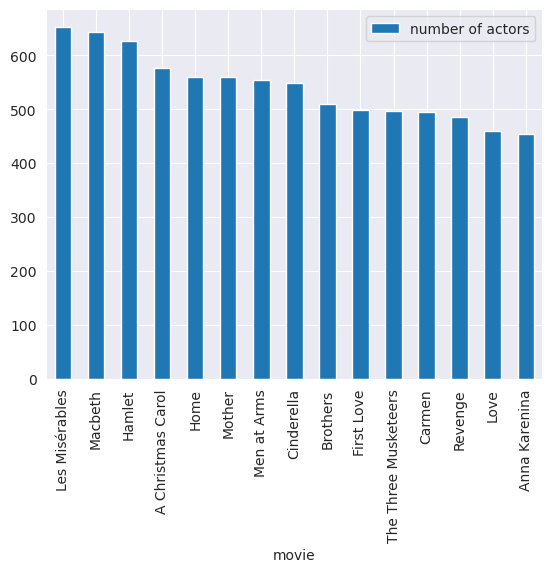

In [57]:
df_actor_per_movie.head(15).plot(kind='bar', x='movie', y='number of actors')